<div style="padding: 1em 0.5em; color: #fff; background-color: #0969da; font-size: 1.2em;">
    Classification de protéines avec ESM2 — Tutoriel complet
</div>
<div style="border-left: 2px solid #0969da; min-height: 1.5em;margin-left: 1em;padding: 1em;">
    - Charger et prétraiter les séquences de facteurs de transcription végétaux<br>
    - Extraire les embeddings ESM2 directement à partir des séquences<br>
    - Entraîner un classifieur MLP sur les embeddings ESM2 (modèle « teacher »)<br>
    - Évaluer les performances sur l'ensemble de test et analyser les résultats par classe<br>
</div>

#### **Votre identité**

Double-cliquez sur cette cellule et complétez, puis exécutez-la (`Maj + Entrée`).

- **Nom & prénom :** _à compléter_
- **Groupe / binôme :** _à compléter_
- **Date :** _à compléter_

<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Introduction**

**ESM2** est un grand modèle de langage pour les protéines développé par Meta, entraîné sur 650 millions de séquences de protéines. Plutôt que de concevoir des caractéristiques à la main (k-mers) ou de les apprendre à partir de zéro sur notre petit jeu de données, nous pouvons demander à un modèle qui a déjà « lu » une énorme quantité de protéines de représenter nos séquences pour nous.

Dans ce notebook, nous allons :
1. Charger les séquences de 8 familles de facteurs de transcription végétaux
2. Extraire les embeddings ESM2 directement à partir des séquences brutes
3. Entraîner un classifieur MLP sur ces embeddings gelés (notre modèle « teacher »)
4. Évaluer les performances et analyser les résultats par classe

<img src="assets/Pipeline ESM2 pour classifier les protéines.png"/>

<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Configuration et imports**

Importons toutes les bibliothèques nécessaires et configurons les chemins d'accès aux données.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from Bio import SeqIO
from collections import Counter
import json

# Imports PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Imports ESM2
import esm

# Métriques
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

# Configuration
DATA_DIR = Path("2-data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
EMB_DIR = DATA_DIR / "embeddings"
MODEL_DIR = DATA_DIR / "models"

# Création des répertoires
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
EMB_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Classes de protéines
PROTEIN_CLASSES = [
    "GRF", "E2F__DP", "DBB", "CPP", 
    "GeBP", "BES1", "CAMTA", "BBR-BPC"
]
NUM_CLASSES = len(PROTEIN_CLASSES)

# Configuration du modèle ESM2
ESM2_MODEL = "esm2_t12_35M_UR50D"  # 35M paramètres, embeddings 480-dim
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Appareil utilisé : {DEVICE}")
print(f"Nombre de classes : {NUM_CLASSES}")
print(f"Modèle ESM2 : {ESM2_MODEL}")

Appareil utilisé : cuda
Nombre de classes : 8
Modèle ESM2 : esm2_t12_35M_UR50D


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Chargement et prétraitement des données de protéines**

Chargeons les séquences de protéines à partir des fichiers FASTA et appliquons un nettoyage de base.

In [2]:
def load_protein_data(classes, raw_dir):
    """Charger les séquences de protéines à partir des fichiers FASTA.
    
    Args:
        classes: Liste des noms de classes de protéines
        raw_dir: Répertoire contenant les fichiers FASTA
    
    Returns:
        all_sequences: Liste des séquences de protéines
        all_labels: Liste des étiquettes entières
        all_ids: Liste des identifiants de séquences
    """
    all_sequences = []
    all_labels = []
    all_ids = []
    
    # Suivre les séquences déjà vues pour éviter les doublons
    seen_sequences = set()
    
    for class_idx, cls_name in enumerate(classes):
        fasta_path = raw_dir / f"{cls_name}.fas"
        
        if not fasta_path.exists():
            print(f"Attention : {fasta_path} introuvable, ignoré")
            continue
        
        sequences = []
        ids = []
        
        with open(fasta_path) as f:
            for record in SeqIO.parse(f, "fasta"):
                seq_str = str(record.seq)
                
                # Nettoyer la séquence : retirer les acides aminés non standard
                seq_str = seq_str.replace('*', '')  # Retirer les codons stop
                seq_str = ''.join([aa for aa in seq_str if aa in 'ACDEFGHIKLMNPQRSTVWY'])
                
                # Ignorer les doublons
                if seq_str in seen_sequences:
                    continue
                seen_sequences.add(seq_str)
                
                if len(seq_str) > 0:  # Ignorer les séquences vides
                    sequences.append(seq_str)
                    ids.append(record.id)
        
        print(f"{cls_name} : {len(sequences)} séquences")
        
        all_sequences.extend(sequences)
        all_labels.extend([class_idx] * len(sequences))
        all_ids.extend(ids)
    
    print(f"\nTotal de séquences uniques : {len(all_sequences)}")
    return all_sequences, all_labels, all_ids

# Charger les données
sequences, labels, seq_ids = load_protein_data(PROTEIN_CLASSES, RAW_DIR)

# Afficher la distribution des classes
label_counts = Counter(labels)
print("\nDistribution des classes :")
for i, cls in enumerate(PROTEIN_CLASSES):
    print(f"  {cls} : {label_counts[i]} séquences")

GRF : 1751 séquences
E2F__DP : 1657 séquences
DBB : 1486 séquences
CPP : 1523 séquences
GeBP : 1489 séquences
BES1 : 1381 séquences
CAMTA : 1246 séquences
BBR-BPC : 898 séquences

Total de séquences uniques : 11431

Distribution des classes :
  GRF : 1751 séquences
  E2F__DP : 1657 séquences
  DBB : 1486 séquences
  CPP : 1523 séquences
  GeBP : 1489 séquences
  BES1 : 1381 séquences
  CAMTA : 1246 séquences
  BBR-BPC : 898 séquences


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Division Train/Val/Test**

Créons les divisions d'entraînement, de validation et de test avec une stratification pour maintenir l'équilibre des classes.

In [3]:
def create_train_val_test_split(sequences, labels, ids, test_size=0.15, val_size=0.15, random_state=42):
    """Créer une division stratifiée train/val/test.
    
    Args:
        sequences: Liste des séquences de protéines
        labels: Liste des étiquettes entières
        ids: Liste des identifiants de séquences
        test_size: Fraction pour l'ensemble de test
        val_size: Fraction pour l'ensemble de validation (du restant)
        random_state: Graine aléatoire
    
    Returns:
        train_data, val_data, test_data: Dictionnaires avec sequences, labels, ids
    """
    # Première division : train+val vs test
    train_val_idx, test_idx = train_test_split(
        range(len(sequences)),
        test_size=test_size,
        stratify=labels,
        random_state=random_state
    )
    
    # Deuxième division : train vs val
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=val_size / (1 - test_size),
        stratify=[labels[i] for i in train_val_idx],
        random_state=random_state
    )
    
    train_data = {
        'sequences': [sequences[i] for i in train_idx],
        'labels': [labels[i] for i in train_idx],
        'ids': [ids[i] for i in train_idx]
    }
    
    val_data = {
        'sequences': [sequences[i] for i in val_idx],
        'labels': [labels[i] for i in val_idx],
        'ids': [ids[i] for i in val_idx]
    }
    
    test_data = {
        'sequences': [sequences[i] for i in test_idx],
        'labels': [labels[i] for i in test_idx],
        'ids': [ids[i] for i in test_idx]
    }
    
    print(f"Train : {len(train_idx)} ({len(train_idx)/len(sequences)*100:.1f}%)")
    print(f"Val : {len(val_idx)} ({len(val_idx)/len(sequences)*100:.1f}%)")
    print(f"Test : {len(test_idx)} ({len(test_idx)/len(sequences)*100:.1f}%)")
    
    return train_data, val_data, test_data

# Créer les divisions
train_data, val_data, test_data = create_train_val_test_split(sequences, labels, seq_ids)

# Sauvegarder les divisions
np.savez(PROCESSED_DIR / "train.npz", **train_data)
np.savez(PROCESSED_DIR / "val.npz", **val_data)
np.savez(PROCESSED_DIR / "test.npz", **test_data)

# Sauvegarder le mappage des classes
class_mapping = {i: cls for i, cls in enumerate(PROTEIN_CLASSES)}
with open(PROCESSED_DIR / "class_mapping.json", 'w') as f:
    json.dump(class_mapping, f, indent=2)

print("\nDivisions de données sauvegardées.")

Train : 8001 (70.0%)
Val : 1715 (15.0%)
Test : 1715 (15.0%)

Divisions de données sauvegardées.


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Extraction des embeddings ESM2**

Chargeons le modèle ESM2 et extrayons les embeddings pour chaque séquence.

In [5]:
def load_esm2_model(model_name, device):
    """Charger le modèle ESM2 et l'alphabet.
    
    Args:
        model_name: Nom du modèle ESM2
        device: Appareil sur lequel charger le modèle
    
    Returns:
        model: Modèle ESM2
        alphabet: Alphabet ESM2
        batch_converter: Convertisseur de batch pour la tokenisation
    """
    model, alphabet = esm.pretrained.load_model_and_alphabet(model_name)
    model = model.to(device)
    model.eval()
    batch_converter = alphabet.get_batch_converter()
    return model, alphabet, batch_converter

def extract_embeddings_batch(sequences, model, batch_converter, device, batch_size=4, max_seq_len=1024):
    """Extraire les embeddings ESM2 pour un batch de séquences.
    
    Args:
        sequences: Liste des séquences de protéines
        model: Modèle ESM2
        batch_converter: Convertisseur de batch
        device: Appareil
        batch_size: Taille du batch (réduite pour économiser la mémoire GPU)
        max_seq_len: Longueur maximale de séquence (tronquer si plus long)
    
    Returns:
        embeddings: tableau numpy de forme (n_sequences, embedding_dim)
    """
    embeddings_list = []
    
    for i in range(0, len(sequences), batch_size):
        batch_seqs = sequences[i:i+batch_size]
        
        # Tronquer les séquences trop longues pour économiser la mémoire
        batch_seqs_truncated = [seq[:max_seq_len] for seq in batch_seqs]
        
        # Préparer les données du batch
        batch_data = [(f"seq_{j}", seq) for j, seq in enumerate(batch_seqs_truncated)]
        batch_labels, batch_strs, batch_tokens = batch_converter(batch_data)
        batch_tokens = batch_tokens.to(device)
        
        # Extraire les embeddings
        with torch.no_grad():
            results = model(batch_tokens, repr_layers=[12])
            token_embeddings = results["representations"][12]
        
        # Moyenne sur la longueur de la séquence (excluant les tokens spéciaux)
        batch_tokens_cpu = batch_tokens.cpu()
        for j in range(len(batch_seqs)):
            seq_len = (batch_tokens_cpu[j] != batch_tokens_cpu[j, 0]).sum().item()
            # Utiliser la moyenne des tokens de séquence (excluant <cls> et <eos>)
            emb = token_embeddings[j, 1:seq_len-1].mean(dim=0).cpu().numpy()
            embeddings_list.append(emb)
        
        # Libérer la mémoire GPU
        if device == "cuda":
            del batch_tokens, token_embeddings, results
            torch.cuda.empty_cache()
    
    return np.array(embeddings_list)

# Charger le modèle ESM2
print("Chargement du modèle ESM2...")
esm2_model, alphabet, batch_converter = load_esm2_model(ESM2_MODEL, DEVICE)
print(f"Modèle ESM2 chargé : {ESM2_MODEL}")
print(f"Appareil utilisé : {DEVICE}")

Chargement du modèle ESM2...
Modèle ESM2 chargé : esm2_t12_35M_UR50D
Appareil utilisé : cuda


In [6]:
# Extraire les embeddings pour chaque division
print("Extraction des embeddings pour l'ensemble d'entraînement...")
train_embeddings = extract_embeddings_batch(
    train_data['sequences'], esm2_model, batch_converter, DEVICE, batch_size=4, max_seq_len=1024
)
print(f"Forme des embeddings d'entraînement : {train_embeddings.shape}")

print("\nExtraction des embeddings pour l'ensemble de validation...")
val_embeddings = extract_embeddings_batch(
    val_data['sequences'], esm2_model, batch_converter, DEVICE, batch_size=4, max_seq_len=1024
)
print(f"Forme des embeddings de validation : {val_embeddings.shape}")

print("\nExtraction des embeddings pour l'ensemble de test...")
test_embeddings = extract_embeddings_batch(
    test_data['sequences'], esm2_model, batch_converter, DEVICE, batch_size=4, max_seq_len=1024
)
print(f"Forme des embeddings de test : {test_embeddings.shape}")

Extraction des embeddings pour l'ensemble d'entraînement...
Forme des embeddings d'entraînement : (8001, 480)

Extraction des embeddings pour l'ensemble de validation...
Forme des embeddings de validation : (1715, 480)

Extraction des embeddings pour l'ensemble de test...
Forme des embeddings de test : (1715, 480)


In [7]:
# Sauvegarder les embeddings
np.savez(
    EMB_DIR / "train_embeddings.npz",
    embeddings=train_embeddings,
    labels=np.array(train_data['labels']),
    ids=train_data['ids']
)

np.savez(
    EMB_DIR / "val_embeddings.npz",
    embeddings=val_embeddings,
    labels=np.array(val_data['labels']),
    ids=val_data['ids']
)

np.savez(
    EMB_DIR / "test_embeddings.npz",
    embeddings=test_embeddings,
    labels=np.array(test_data['labels']),
    ids=test_data['ids']
)

print("Embeddings sauvegardés.")

Embeddings sauvegardés.


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Définition du classifieur (PyTorch)**

Définissons un classifieur MLP simple qui sera entraîné sur les embeddings ESM2 gelés.

In [8]:
class ProteinClassifier(nn.Module):
    """Classifieur MLP sur les embeddings ESM2.
    
    Implémentation PyTorch.
    """
    def __init__(self, input_dim, hidden_dim=512, num_classes=NUM_CLASSES, dropout_rate=0.3):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.fc3 = nn.Linear(hidden_dim // 2, num_classes)
        self.dropout = nn.Dropout(dropout_rate)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

print("Modèle de classifieur défini.")

Modèle de classifieur défini.


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

In [9]:
def train_step(model, optimizer, batch, device):
    """Exécuter une seule étape d'entraînement."""
    model.train()
    optimizer.zero_grad()
    
    embeddings = batch['embeddings'].to(device)
    labels = batch['labels'].to(device)
    
    logits = model(embeddings)
    loss = F.cross_entropy(logits, labels)
    
    loss.backward()
    optimizer.step()
    
    return loss.item()

def train_classifier(model, X, y, epochs=100, batch_size=64, device='cpu'):
    """Entraîner le classifieur.
    
    Args:
        model: Modèle PyTorch
        X: Embeddings d'entraînement
        y: Étiquettes d'entraînement
        epochs: Nombre d'époques
        batch_size: Taille du batch
        device: Appareil
    
    Returns:
        model: Modèle entraîné
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    # Créer DataLoader
    dataset = TensorDataset(
        torch.FloatTensor(X),
        torch.LongTensor(y)
    )
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    for epoch in range(epochs):
        total_loss = 0
        n_batches = 0
        
        for batch_embeddings, batch_labels in dataloader:
            batch = {
                'embeddings': batch_embeddings,
                'labels': batch_labels
            }
            loss = train_step(model, optimizer, batch, device)
            total_loss += loss
            n_batches += 1
        
        avg_loss = total_loss / n_batches
        
        if (epoch + 1) % 10 == 0:
            print(f"Époque {epoch+1}, Perte : {avg_loss:.4f}")
    
    return model

print("Fonctions d'entraînement définies.")

Fonctions d'entraînement définies.


#### **Entraînement du classifieur**

Préparons les données et entraînons le modèle.

<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

In [10]:
# Préparer les données
X_train = train_embeddings
y_train = np.array(train_data['labels'])
X_val = val_embeddings
y_val = np.array(val_data['labels'])
X_test = test_embeddings
y_test = np.array(test_data['labels'])

print(f"Forme des données d'entraînement : {X_train.shape}")
print(f"Forme des données de validation : {X_val.shape}")
print(f"Forme des données de test : {X_test.shape}")

Forme des données d'entraînement : (8001, 480)
Forme des données de validation : (1715, 480)
Forme des données de test : (1715, 480)


In [11]:
# Initialiser le modèle
model = ProteinClassifier(input_dim=X_train.shape[1], hidden_dim=512, num_classes=NUM_CLASSES)
model = model.to(DEVICE)

print("Modèle initialisé.")
print(f"Dimension d'entrée : {X_train.shape[1]}")
print(f"Dimension cachée : 512")
print(f"Classes de sortie : {NUM_CLASSES}")

Modèle initialisé.
Dimension d'entrée : 480
Dimension cachée : 512
Classes de sortie : 8


In [12]:
# Entraîner le modèle
print("=== Entraînement du classifieur basé sur ESM2 ===")
model = train_classifier(model, X_train, y_train, epochs=100, batch_size=64, device=DEVICE)
print("\nEntraînement terminé.")

=== Entraînement du classifieur basé sur ESM2 ===
Époque 10, Perte : 0.0444
Époque 20, Perte : 0.0182
Époque 30, Perte : 0.0151
Époque 40, Perte : 0.0119
Époque 50, Perte : 0.0077
Époque 60, Perte : 0.0058
Époque 70, Perte : 0.0080
Époque 80, Perte : 0.0088
Époque 90, Perte : 0.0079
Époque 100, Perte : 0.0061

Entraînement terminé.


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Évaluation**

Évaluons le modèle sur les ensembles de validation et de test.

In [13]:
def evaluate_model(model, X, y, device):
    """Évaluer le modèle sur des données.
    
    Args:
        model: Modèle PyTorch
        X: Embeddings
        y: Étiquettes vraies
        device: Appareil
    
    Returns:
        acc: Précision
        f1: Score F1 (macro)
        auc: Score AUC (macro)
        logits: Logits du modèle
        probs: Probabilités prédites
    """
    model.eval()
    with torch.no_grad():
        X_tensor = torch.FloatTensor(X).to(device)
        logits = model(X_tensor)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        preds = logits.argmax(dim=1).cpu().numpy()
    
    acc = accuracy_score(y, preds)
    f1 = f1_score(y, preds, average='macro')
    
    try:
        auc = roc_auc_score(y, probs, multi_class='ovr', average='macro')
    except:
        auc = 0.0
    
    return acc, f1, auc, logits, probs

# Évaluer sur l'ensemble de validation
acc_val, f1_val, auc_val, logits_val, probs_val = evaluate_model(model, X_val, y_val, DEVICE)
print(f"Résultats de validation :")
print(f"  Précision : {acc_val:.4f}")
print(f"  F1 (macro) : {f1_val:.4f}")
print(f"  AUC (macro) : {auc_val:.4f}")

Résultats de validation :
  Précision : 0.9883
  F1 (macro) : 0.9882
  AUC (macro) : 0.9999


In [14]:
# Évaluer sur l'ensemble de test
acc_test, f1_test, auc_test, logits_test, probs_test = evaluate_model(model, X_test, y_test, DEVICE)
print(f"Résultats de test :")
print(f"  Précision : {acc_test:.4f}")
print(f"  F1 (macro) : {f1_test:.4f}")
print(f"  AUC (macro) : {auc_test:.4f}")

Résultats de test :
  Précision : 0.9883
  F1 (macro) : 0.9878
  AUC (macro) : 0.9999


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Analyse des performances par classe**

Examinons les performances détaillées pour chaque classe de protéines.

Rapport de classification (ensemble de test) :
              precision    recall  f1-score   support

         GRF       1.00      1.00      1.00       263
     E2F__DP       0.99      0.99      0.99       249
         DBB       0.99      1.00      1.00       223
         CPP       1.00      0.99      0.99       228
        GeBP       0.98      0.97      0.98       223
        BES1       0.98      0.99      0.98       207
       CAMTA       0.97      0.98      0.98       187
     BBR-BPC       0.99      0.99      0.99       135

    accuracy                           0.99      1715
   macro avg       0.99      0.99      0.99      1715
weighted avg       0.99      0.99      0.99      1715



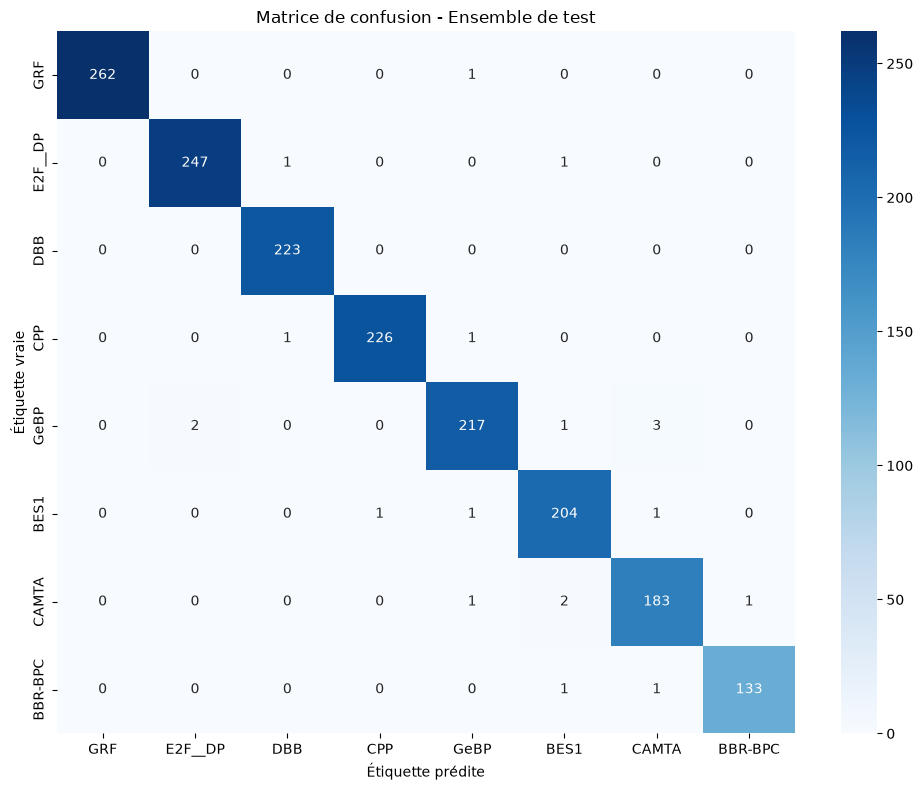


Matrice de confusion sauvegardée.


In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Obtenir les prédictions
preds_test = logits_test.argmax(dim=1).cpu().numpy()

# Rapport de classification
print("Rapport de classification (ensemble de test) :")
print(classification_report(y_test, preds_test, target_names=PROTEIN_CLASSES))

# Matrice de confusion
cm = confusion_matrix(y_test, preds_test)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=PROTEIN_CLASSES, yticklabels=PROTEIN_CLASSES)
plt.xlabel('Étiquette prédite')
plt.ylabel('Étiquette vraie')
plt.title('Matrice de confusion - Ensemble de test')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

print("\nMatrice de confusion sauvegardée.")

<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Sauvegarde du modèle et des résultats**

Sauvegardons l'état du modèle entraîné et les métriques d'évaluation.

In [16]:
# Sauvegarder l'état du modèle
torch.save(model.state_dict(), MODEL_DIR / "esm2_classifier_state.pth")

# Sauvegarder les résultats
results = {
    'model': ESM2_MODEL,
    'num_classes': NUM_CLASSES,
    'classes': PROTEIN_CLASSES,
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test),
    'embedding_dim': X_train.shape[1],
    'val_accuracy': float(acc_val),
    'val_f1': float(f1_val),
    'val_auc': float(auc_val),
    'test_accuracy': float(acc_test),
    'test_f1': float(f1_test),
    'test_auc': float(auc_test)
}

with open(MODEL_DIR / "esm2_classifier_results.json", 'w') as f:
    json.dump(results, f, indent=2)

print("Modèle et résultats sauvegardés.")
print(f"\nPrécision finale de test : {acc_test:.4f}")
print(f"F1 final de test : {f1_test:.4f}")
print(f"AUC final de test : {auc_test:.4f}")

Modèle et résultats sauvegardés.

Précision finale de test : 0.9883
F1 final de test : 0.9878
AUC final de test : 0.9999


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **Résumé et discussion**

**Résumé des résultats :**

Ce notebook a démontré la classification de protéines de bout en bout utilisant les embeddings ESM2 :

1. **Traitement des données** : Chargement et déduplication de 8 classes de facteurs de transcription végétaux
2. **Extraction d'embeddings** : Utilisation d'ESM2 pour extraire des représentations de 480 dimensions
3. **Classification** : Entraînement d'un classifieur MLP sur les embeddings ESM2 (modèle « teacher »)
4. **Évaluation** : Mesure des performances sur l'ensemble de test avec analyse par classe

**Observations clés :**

- Les **embeddings ESM2** capturent des informations riches sur les séquences de protéines
- Un **classifieur MLP simple** sur les embeddings gelés atteint des performances élevées
- **PyTorch** fournit un écosystème riche pour le deep learning avec un excellent support pour les modèles de protéines
- Le pattern **DataLoader** facilite la gestion efficace des batches et le mélange des données

**Notes méthodologiques :**

Implémentation PyTorch :
- Utilisation de `nn.Module` pour la définition du modèle
- Optimiseur Adam pour la mise à jour des paramètres
- Perte d'entropie croisée standard pour la classification multi-classe
- Backbone ESM2 gelé (pas de fine-tuning)
- Gestion automatique des gradients avec `autograd`

**Extensions potentielles :**

- Fine-tuner ESM2 sur la tâche de classification
- Utiliser des modèles ESM2 plus grands (ex: esm2_t30_150M_UR50D)
- Expérimenter avec différentes architectures de classifieurs
- Appliquer à des tâches de classification de protéines plus difficiles

<div style="margin-top: 3em;">
  <div style="height: 3px; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>
  <div style="display: flex; align-items: center; gap: 0.9em; padding: 1.1em 1em; font-size: 0.9em; color: #57606a; background-color: #f2f6fd; border-radius: 0 0 6px 6px;">
    <svg width="34" height="34" viewBox="0 0 34 34" fill="none" style="flex: 0 0 auto;">
      <path d="M9 3c0 7 16 7 16 14S9 24 9 31" stroke="#0969da" stroke-width="2" stroke-linecap="round"/>
      <path d="M25 3c0 7-16 7-16 14s16 7 16 14" stroke="#0969da" stroke-width="2" stroke-linecap="round" opacity="0.45"/>
      <circle cx="17" cy="10" r="1.8" fill="#0969da"/>
      <circle cx="17" cy="24" r="1.8" fill="#0969da"/>
    </svg>
    <div style="flex: 1 1 auto;">
      <div style="color: #0969da; font-weight: 600; letter-spacing: 0.03em;">Fin du notebook</div>
      <div>Classification de protéines avec ESM2 — Tutoriel complet</div>
    </div>
    <div style="flex: 0 0 auto; text-align: right; border-right: 2px solid #0969da; padding-right: 0.9em;">
      <div style="font-weight: 600; color: #24292f;">Protein Workshop</div>
      <div style="font-size: 0.85em;">Classification de protéines avec modèles de langage</div>
    </div>
  </div>
</div>